## Problem Statement:

### You are the Data Scientist at a telecom company “Leo” whose customers are churning out to its competitors. You have to analyse the data of your company and find insights and stop your customers from churning out to other telecom companies.

## Customer_churn Dataset:

### The details regarding this ‘customer_churn’ dataset are present in the data dictionary:

## Domain Context –  

### Customer churn, in simple terms means that the customer has stopped doing business with the company and this is a common problem when it comes to telecom industries. To avoid this, companies use predictive analysis to gauge the factors responsible for a customer to leave the company. These churn prediction models help in finding out the customer base that are most likely to churn out.

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Load dataset

In [2]:
# Load dataset
df = pd.read_csv('/content/customer_churn.csv')

In [13]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [14]:
# View first 5 records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Check shape (Rows , columns) of data
df.shape

(7043, 21)

In [6]:
# Information about dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### 1. From above list, it is observed that TotalCharges column should be of Numeric but currently it is Object type.

#### 2. Multiple columns are of categorical type data.

In [10]:
#Check dataset columns
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [11]:
# Check null values in dataset
df.isnull().sum().sum()

np.int64(0)

In [12]:
# check duplicate values in dataset
df.duplicated().sum()

np.int64(0)

## A. Data Manipulation:

In [19]:
# a. Find the total number of male customers
df[df['gender'] == 'Male'].shape[0]

3555

In [20]:
# b. Find the total number of customers whose Internet Service is ‘DSL’
df[df['InternetService'] == 'DSL'].shape[0]

2421

In [28]:
# c. Extract all the Female senior citizens whose Payment Method is Mailed check & store the result in ‘new_customer’
new_customer = df[(df['SeniorCitizen']==1) & (df['gender'] == 'Female') & (df['PaymentMethod'] == 'Mailed check')]
print(new_customer.shape[0])

50


In [32]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors='coerce')

In [34]:
# d. Extract all those customers whose tenure is less than 10 months or their Total charges is less than 500$ & store the result in ‘new_customer’
cust = df[(df['tenure']<10) | (df['TotalCharges']<500)]
print(cust.shape[0])

2233


## B. Data Visualization:

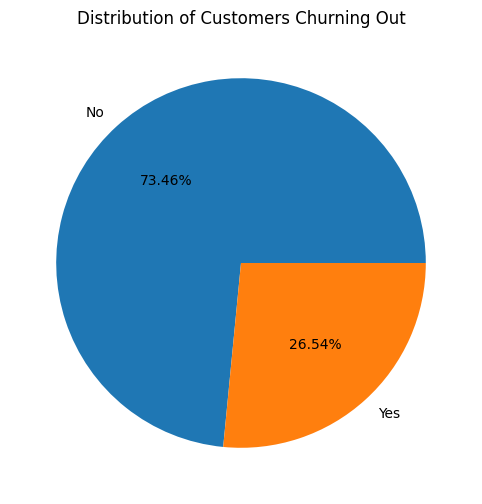

In [38]:
# a. Build a pie-chart to show the distribution of customers would be churning out

cust_churn = df['Churn'].value_counts()
plt.figure(figsize=(10,6))
plt.pie(cust_churn,labels=cust_churn.index,autopct='%1.2f%%')
plt.title('Distribution of Customers Churning Out')
plt.show()

In [43]:
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


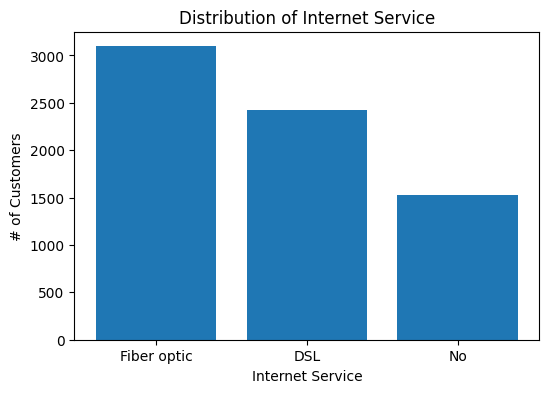

In [46]:
# b. Build a bar-plot to show the distribution of ‘Internet Service’

plt.figure(figsize=(6,4))

plt.bar(df['InternetService'].value_counts().index,df['InternetService'].value_counts())
plt.title('Distribution of Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('# of Customers')
plt.show()

## C) Model Building:

a. Build a sequential model using Keras, to find out if the customerwouldchurn or not, using ‘tenure’ as the feature and ‘Churn’ as the dependent/target column:

i. The visible/input layer should have 12 nodes with ‘Relu’ as activation function.

ii. This model would have 1 hidden layer with 8 nodes and ‘Relu’ as activation function  

iii. Use ‘Adam’ as the optimization algorithm

iv. Fit the model on the train set, with number of epochs to be 150

v. Predict the values on the test set and build a confusion matrix  

vi. Plot the ‘Accuracy vs Epochs’ graph

In [47]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [53]:
df[pd.isnull(df['TotalCharges'])]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


### As observed, tenture is also 0 for these records so total charge can be mentioned as 0

In [54]:
# Replace missing values with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [56]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [58]:
df['Churn'] = df['Churn'].map({'Yes':1,'No':0})

In [59]:
df['Churn'].value_counts()

,count
Churn,
0,5174
1,1869


In [60]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [61]:
X = df[['tenure']]

y = df['Churn']

In [62]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42, stratify=y)

In [63]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [64]:
#Build ANN model

model1 = Sequential()

# Input layer
model1.add(Dense(12, input_dim=1, activation='relu'))

# Hidden layer
model1.add(Dense(8, activation='relu'))

# Output layer
model1.add(Dense(1, activation='sigmoid'))

# Compile model
model1.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137 (548.00 B)

 Trainable params: 137 (548.00 B)

 Non-trainable params: 0 (0.00 B)

In [65]:
# Train model
history1 = model1.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7337 - loss: 0.5628 - val_accuracy: 0.7382 - val_loss: 0.5267
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7337 - loss: 0.5205 - val_accuracy: 0.7382 - val_loss: 0.5196
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7337 - loss: 0.5161 - val_accuracy: 0.7382 - val_loss: 0.5177
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7380 - loss: 0.5137 - val_accuracy: 0.7338 - val_loss: 0.5170
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7406 - loss: 0.5119 - val_accuracy: 0.7338 - val_loss: 0.5163
Epoch 6/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7455 - loss: 0.5110 - val_accuracy: 0.7418 - val_loss: 0.5180
Epoch 7/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7462 - loss: 0.5108 - val_accuracy: 0.7400 - val_loss: 0.5165
Epoch 8/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7497 - loss: 0.5105 - val_accu

In [66]:
# Prediction

y_pred = model1.predict(X_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [67]:
y_pred

array([[0.05926951],
       [0.43335888],
       [0.21240187],
       ...,
       [0.50261414],
       [0.14037032],
       [0.05926951]], shape=(1409, 1), dtype=float32)

In [68]:
# Convert probabilities into 0 and 1
y_pred = (y_pred > 0.5).astype(int)

In [69]:
y_pred

array([[0],
       [0],
       [0],
       ...,
       [1],
       [0],
       [0]], shape=(1409, 1))

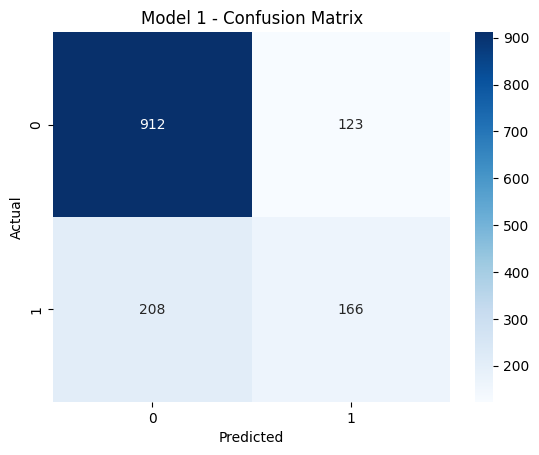

In [70]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Model 1 - Confusion Matrix')

plt.show()

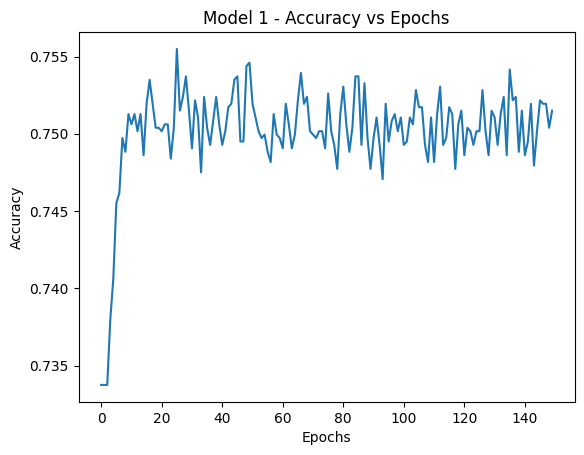

In [71]:
# Accuracy vs Epochs

plt.plot(history1.history['accuracy'])

plt.title('Model 1 - Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.show()

### b. Build the 2nd model using same target and feature variables:

i. Add a drop-out layer after the input layer with drop-out value of 0.3

ii. Add a drop-out layer after the hidden layer with drop-out value of 0.2

iii. Predict the values on the test set and build a confusion matrix

iv. Plot the ‘Accuracy vs Epochs’ graph



In [72]:
model2 = Sequential()

# Input layer
model2.add(Dense(12, input_dim=1, activation='relu'))

# First dropout
model2.add(Dropout(0.3))

# Hidden layer
model2.add(Dense(8, activation='relu'))

# Second dropout
model2.add(Dropout(0.2))

# Output layer
model2.add(Dense(1, activation='sigmoid'))

# Compile model
model2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 12)             │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137 (548.00 B)

 Trainable params: 137 (548.00 B)

 Non-trainable params: 0 (0.00 B)

In [73]:
# Train model
history2 = model2.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7151 - loss: 0.6408 - val_accuracy: 0.7382 - val_loss: 0.5890
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7342 - loss: 0.5613 - val_accuracy: 0.7382 - val_loss: 0.5278
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7364 - loss: 0.5366 - val_accuracy: 0.7382 - val_loss: 0.5193
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7326 - loss: 0.5373 - val_accuracy: 0.7382 - val_loss: 0.5199
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7331 - loss: 0.5361 - val_accuracy: 0.7382 - val_loss: 0.5194
Epoch 6/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7329 - loss: 0.5291 - val_accuracy: 0.7382 - val_loss: 0.5185
Epoch 7/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7386 - loss: 0.5276 - val_accuracy: 0.7382 - val_loss: 0.5182
Epoch 8/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7446 - loss: 0.5281 - val_accu

In [74]:
# Prediction

y_pred2 = model2.predict(X_test)

y_pred2 = (y_pred2 > 0.5).astype(int)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


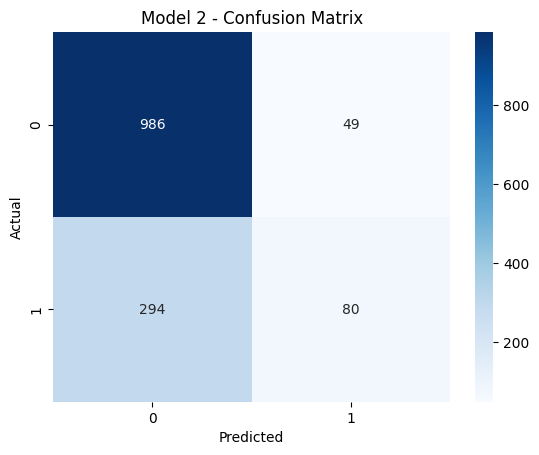

In [75]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred2)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Model 2 - Confusion Matrix')

plt.show()

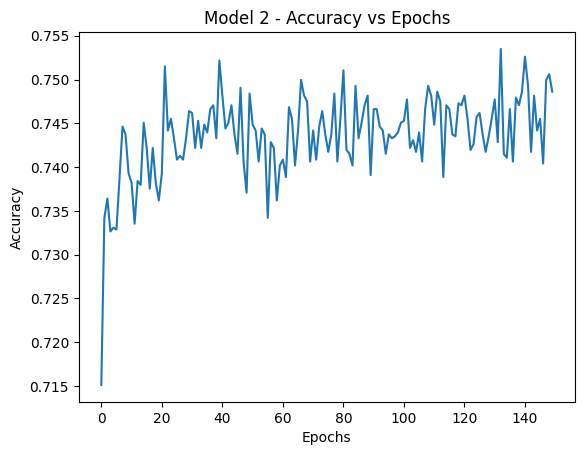

In [76]:
# Accuracy vs Epochs
plt.plot(history2.history['accuracy'])

plt.title('Model 2 - Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.show()

### c. Build the 3rd model using ‘Tenure’, ’Monthly Charges’ & ‘Total Charges’ as the features and ‘Churn’ as the dependent/target column:  

i. The visible/input layer should have 12 nodes with ‘Relu’ as activation function.

ii. This model would have 1 hidden layer with 8 nodes and ‘Relu’ as activation function

iii. Use ‘Adam’ as the optimization algorithm

iv. Fit the model on the train set, with number of epochs to be 150

v. Predict the values on the test set and build a confusion matrix

vi. Plot the ‘Accuracy vs Epochs’ graph

In [77]:
X = df[['tenure', 'MonthlyCharges', 'TotalCharges']]

y = df['Churn']

In [78]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

In [79]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [80]:
model3 = Sequential()

# Input layer
model3.add(Dense(12, input_dim=3, activation='relu'))

# Hidden layer
model3.add(Dense(8, activation='relu'))

# Output layer
model3.add(Dense(1, activation='sigmoid'))

# Compile model
model3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model3.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 12)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [81]:
history3 = model3.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7337 - loss: 0.5616 - val_accuracy: 0.7382 - val_loss: 0.5025
Epoch 2/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7557 - loss: 0.4840 - val_accuracy: 0.7764 - val_loss: 0.4801
Epoch 3/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7739 - loss: 0.4670 - val_accuracy: 0.7746 - val_loss: 0.4753
Epoch 4/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7748 - loss: 0.4618 - val_accuracy: 0.7657 - val_loss: 0.4741
Epoch 5/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7750 - loss: 0.4583 - val_accuracy: 0.7649 - val_loss: 0.4739
Epoch 6/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7781 - loss: 0.4562 - val_accuracy: 0.7728 - val_loss: 0.4717
Epoch 7/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7801 - loss: 0.4548 - val_accuracy: 0.7764 - val_loss: 0.4705
Epoch 8/150
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7843 - loss: 0.4532 - val_accu

In [82]:
# Predict Values
y_pred3 = model3.predict(X_test)

y_pred3 = (y_pred3 > 0.5).astype(int)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


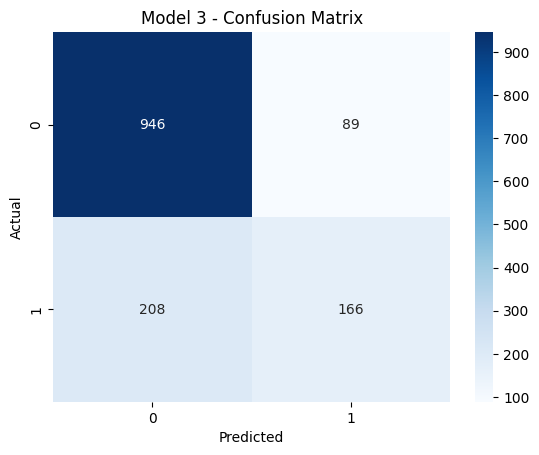

In [83]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred3)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Model 3 - Confusion Matrix')

plt.show()

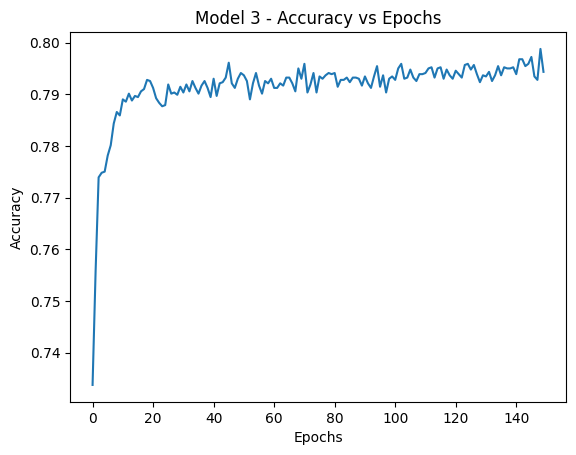

In [84]:
# Accuracy vs Epoch

plt.plot(history3.history['accuracy'])

plt.title('Model 3 - Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.show()

In [85]:
from sklearn.metrics import accuracy_score

print("Model 1 Accuracy:", accuracy_score(y_test, y_pred))
print("Model 2 Accuracy:", accuracy_score(y_test, y_pred2))
print("Model 3 Accuracy:", accuracy_score(y_test, y_pred3))

Model 1 Accuracy: 0.7650816181689141
Model 2 Accuracy: 0.7565649396735273
Model 3 Accuracy: 0.7892122072391767
